In [8]:
def PatternCount(Text, Pattern):
    count = 0
    for i in range(len(Text) - len(Pattern) + 1):
        if Text[i:i+len(Pattern)] == Pattern:
            count += 1
    return count


text = "CCGACAACGCACAACGCGAGACAACGCCCACAACGCTCACACAACGCATTCAGACAACGCACAACGCCCGCAACAACGCTACAACGCATACAACGCGCGACAACGCAAGCAAGCAATCAACACAACGCACAACGCTACAACGCCACAACGCACAACGCCCACAACGCGACAACGCACAACGCAAAGACAACGCTTAGTACAACGCACAACGCTTGACAACGCACAACGCACAACGCGTAAGGAACAACGCACAACGCCCAATACATATACAACGCACAACGCACAACGCAACAACGCACAACGCCGACAACGCTCGTTACAACGCACAACGCACAACGCACAACGCCGACAACGCACAACGCCTCTTTAAATACAACGCCAACCTCAACAACGCACAACGCTGTTACAACGCGACAACGCGGACAACGCGTACAACGCAACAACGCTAAATACAACGCTTGGACAACGCAACAACGCACAACGCACAACGCACAACGCAGACAACGCTACAACGCCGCACAACGCACAACGCGTGGTACAACGCAACAACGCACAACGCCGACAACGCCGACAACGCCTCGTTGGGACAACGCACAACGCGGAACAACGCACAACGCTCCGACCAGTGACAACGCACAACGCAACAACGCGAGCCACAACGCTCAACAACGCGTAAACAGACGGACAACGCACAACGCACAACGCACAACGCGAACAACGCGCGACAACGCGTCGTGTTGTATTCGACAACGCATGCTCACAACGCCGATGCAGTACAACGCACAACGCACAACGCCATACAACGCACAACGCTGAACAACGCGTAGCGCGACTCACAACGCCTACAACGCACAACGCCACAACGCGGCACAACGCACAACGCGACATCAACCCACAACGCCGAACAACGCAACAACGCTACAACGCACAACGCACAACGCACAACGCATACAACGCGACACAACGCGACTACAACGCAACAACGCTACAACGCACAACGCTTTAACAACGC"
pattern = "ACAACGCAC"

print(PatternCount(text, pattern))



37


In [24]:

text = "CGCCTAAATAGCCTCGCGGAGCCTTATGTCATACTCGTCCT"
k = 3

def FrequencyTable(text, k):
    freq_map = {}
    for i in range(len(text) - k + 1):
        pattern = text[i:i+k]
        if pattern in freq_map:
            freq_map[pattern] += 1
        else:
            freq_map[pattern] = 1
    return freq_map

def MaxMap(freq_map):
    max_value = 0
    for key in freq_map:
        if freq_map[key] > max_value:
            max_value = freq_map[key]
    return max_value

def FrequentWords(text, k):
    freq_map = FrequencyTable(text, k)
    max_count = MaxMap(freq_map)
    frequent_patterns = []

    for pattern in freq_map:
        if freq_map[pattern] == max_count:
            frequent_patterns.append(pattern)

    return frequent_patterns


freq_map = FrequencyTable(text, k)

print(FrequencyTable(text, k))
print(MaxMap(freq_map))
print(FrequentWords(text, k))
    
    

{'CGC': 2, 'GCC': 3, 'CCT': 4, 'CTA': 1, 'TAA': 1, 'AAA': 1, 'AAT': 1, 'ATA': 2, 'TAG': 1, 'AGC': 2, 'CTC': 2, 'TCG': 2, 'GCG': 1, 'CGG': 1, 'GGA': 1, 'GAG': 1, 'CTT': 1, 'TTA': 1, 'TAT': 1, 'ATG': 1, 'TGT': 1, 'GTC': 2, 'TCA': 1, 'CAT': 1, 'TAC': 1, 'ACT': 1, 'CGT': 1, 'TCC': 1}
4
['CCT']


In [7]:
def reverse_complement(pattern):
    comp = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C', 'a': 't', 't': 'a', 'c': 'g', 'g': 'c'}

    complement = ''.join(comp.get(base, base) for base in pattern)

    return complement[::-1]

sequence = ""
print(reverse_complement(sequence))

GCTAGCTAGCTAGCTAGCTAGCTAGCTAGCTAGCTACGAT


In [31]:
def PatternCount(Text, Pattern):
    count = 0
    for i in range(len(Text) - len(Pattern) + 1):
        if Text[i:i+len(Pattern)] == Pattern:
            count += 1
    return count

def PatternPositions(Text, Pattern):
    positions = []
    for i in range(len(Text) - len(Pattern) + 1):
        if Text[i:i+len(Pattern)] == Pattern:
            positions.append(i)
    return positions
def reverse_complement(dna):
    comp = {
        'A': 'T', 'T': 'A',
        'C': 'G', 'G': 'C',
        'a': 't', 't': 'a',
        'c': 'g', 'g': 'c'
    }
    
    
    complement = ''.join(comp.get(base, base) for base in dna)
    
    
    return complement[::-1]


with open("Vibrio_cholerae.txt", "r") as file:
    text = file.read().strip()

Pattern = "CTTGATCAT"
positions = PatternPositions(text, Pattern)
pattern_rc = reverse_complement(Pattern)

print(pattern_rc)
print(*positions)
print(PatternCount(text, Pattern))

ATGATCAAG
60039 98409 129189 152283 152354 152411 163207 197028 200160 357976 376771 392723 532935 600085 622755 1065555
16


In [33]:
def find_clumps(genome, k, L, t):
    clumps = set()
    freq = {}

    # First window
    window = genome[:L]
    for i in range(L - k + 1):
        kmer = window[i:i+k]
        freq[kmer] = freq.get(kmer, 0) + 1

    # Add k-mers that appear at least t times
    for kmer, count in freq.items():
        if count >= t:
            clumps.add(kmer)

    # Slide the window across the genome
    for i in range(1, len(genome) - L + 1):
        # Remove the k-mer leaving the window
        old_kmer = genome[i-1:i-1+k]
        freq[old_kmer] -= 1

        # Add the k-mer entering the window
        new_kmer = genome[i+L-k:i+L]
        freq[new_kmer] = freq.get(new_kmer, 0) + 1

        # Check if new_kmer forms a clump
        if freq[new_kmer] >= t:
            clumps.add(new_kmer)

    return clumps

with open("Vibrio_cholerae.txt", "r") as file:
    genome = file.read().strip()

k = 9
L = 500
t = 3

clump_kmers = find_clumps(genome, k, L, t)
print(*clump_kmers)

AAACTCAAA CCCCCCCCC GGGAGGTTG TCAGGTAAG TCCCCCTTA CATGATCAT CTTATAGGG GGTATTTCG TATAAACAA GATTTTTGA ATTGCGGAT TTTGGTTTC AAGTCAGGT CACACACAC TTACTGTGT TGCGGATGT CGTGGTGGT GGAGGGGGT ATTTTTGAT TTATCGGTT GTTGGGAGG GGTAAGTCA GGGTATTTC TGTTATTGC TTGCATTTT TTGGTCCCA GAGGGGGTA AAGGTGGTC CCCCCTTAT AACAGCAAC TTATTGCGG AGGTAAGTC CACCAAACT CTTAAAGAT AGGTTGGGA TTTGCATTT CTGGTTCTG CAAAACCCT TGCCGAGTA CTCCCCCTT TAAGTCAGG CAACAGCAA GGTTGGGAG GGGGTATTT TCTATAAAC GTATTTCGC TTTGGTCCC ACTCACACT GGGGAGGTT GTTATTGCG CGTGTTTGC TGGGAGGGG TATTGCGGA GCAGCAACA CAACAACAA AAAAACTGA GTAAGTCAG TTGTAAAAT TGATTTTCA TGATTTTTG CCTCCCCCT CTCTTGATC TTTTGATTT AGCATGATC GATGTTATT TTCTGGTTC TCTTTTTCA CAGCAACAA AGCAACAAG TAAAGATTC CCTTATAGG CGGATGTTA ATTGGGACT TCACCAATC GCCGAGTAA AGAGAGAGA AGCAACAGC GGGGGGGGG ATGTTATTG CGCCAGATG CAGGTAAGT TTGGGAGGG GGTTCTGGT TTGCGGATG CTATAAACA GAGGTTGGG GAAGGCATC GGATGTTAT CTTGATCAT AGGGGGTAT GCGGATGTT AGTCAGGTA CCCTTATAG TGGTCCCAT ATAAACAAT CACGCGTTG AAATAAATA TCTTGATCA GTCAGGTAA TCTGGTTCT 

In [10]:

def minimum_skew(genome):
    skew = 0
    skew_values = [0]

    for nucleotide in genome:
        if nucleotide == 'G':
            skew += 1
        elif nucleotide == 'C':
            skew -= 1

        skew_values.append(skew)
    min_skew = min(skew_values)

    positions = [
        i for i, value in enumerate(skew_values)
        if value == min_skew
    ]

    return positions

# Test with sample input
genome = "TAAAGACTGCCGAGAGGCCAACACGAGTGCTAGAACGAGGGGCGTAAACGCGGGTCCGAT"

result = minimum_skew(genome)

print(*result)

11 24


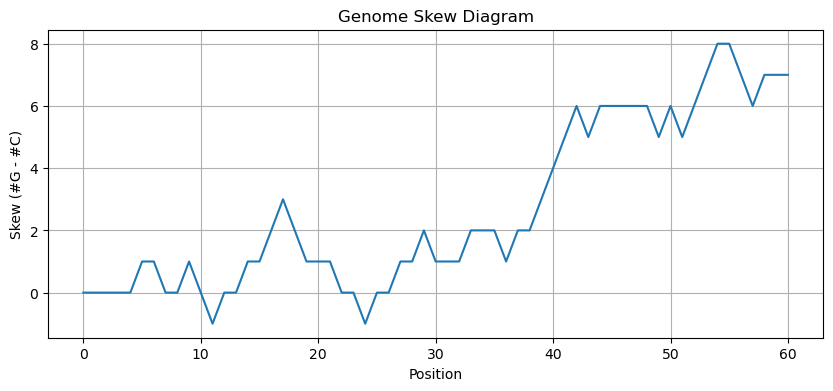

In [9]:
import matplotlib.pyplot as plt

def skew_diagram(genome):
    skew = 0
    values = [0]

    for nucleotide in genome:
        if nucleotide == 'G':
            skew += 1
        elif nucleotide == 'C':
            skew -= 1

        values.append(skew)

    return values


genome = "TAAAGACTGCCGAGAGGCCAACACGAGTGCTAGAACGAGGGGCGTAAACGCGGGTCCGAT"


skew_values = skew_diagram(genome)

plt.figure(figsize=(10,4))
plt.plot(skew_values)
plt.xlabel("Position")
plt.ylabel("Skew (#G - #C)")
plt.title("Genome Skew Diagram")
plt.grid(True)
plt.show()